<a href="https://colab.research.google.com/github/g25ait2023/DEEP-LEARNING_NLP/blob/main/flowers_G25AIT2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np

In [8]:
# each point is length, width, type (0, 1)

data = [[3,   1.5, 1],
        [2,   1,   0],
        [4,   1.5, 1],
        [3,   1,   0],
        [3.5, .5,  1],
        [2,   .5,  0],
        [5.5,  1,  1],
        [1,    1,  0]]

#mystery_flower = [4.5, 1]
#mystery_flower = [1.5, 0.8]   # on changing mystery_flower values we will see the predict  what the new myster flower cooordinate belongs to (in class activity)
mystery_flower = [5, 1.5]

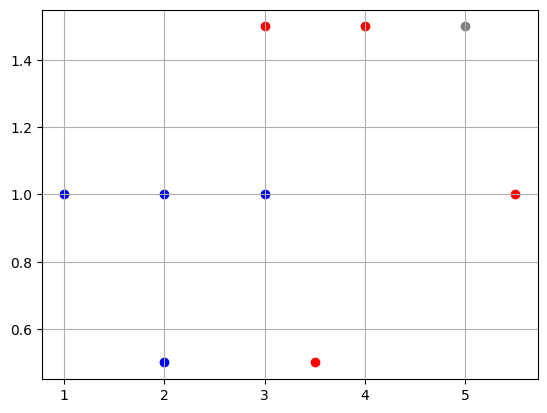

In [9]:
# scatter plot them
def vis_data():
    plt.grid()

    for i in range(len(data)):
        c = 'r'
        if data[i][2] == 0:
            c = 'b'
        plt.scatter([data[i][0]], [data[i][1]], c=c)

    plt.scatter([mystery_flower[0]], [mystery_flower[1]], c='gray')

vis_data()

In [10]:
# network

#       o  flower type
#      / \  w1, w2, b
#     o   o  length, width

In [11]:
# activation function

def sigmoid(x):
    return 1/(1+np.exp(-x))

def sigmoid_p(x):
    return sigmoid(x) * (1-sigmoid(x))

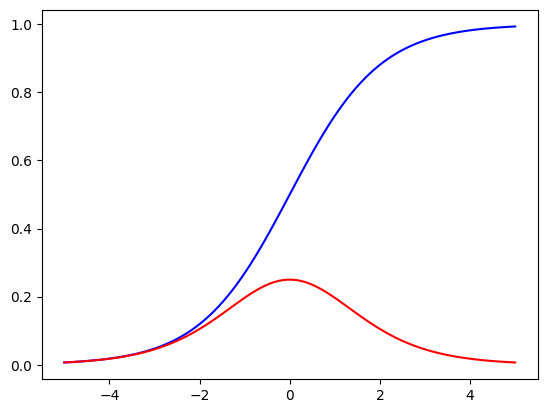

In [12]:
X = np.linspace(-5, 5, 100)

plt.plot(X, sigmoid(X), c="b") # sigmoid in blue
fig = plt.plot(X, sigmoid_p(X), c="r") # sigmoid_p in red

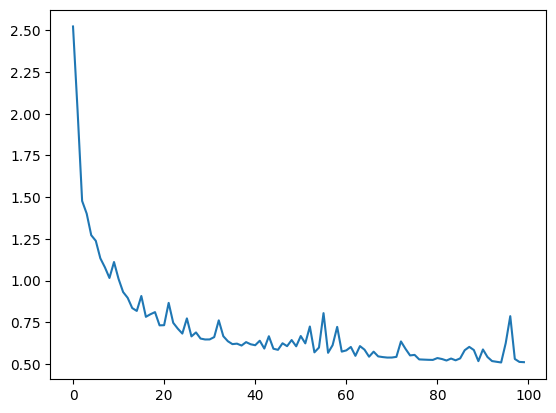

In [13]:
# train

def train():
    #random init of weights
    w1 = np.random.randn()
    w2 = np.random.randn()
    b = np.random.randn()

    iterations = 10000
    learning_rate = 0.1
    costs = [] # keep costs during training, see if they go down

    for i in range(iterations):
        # get a random point
        ri = np.random.randint(len(data))
        point = data[ri]

        z = point[0] * w1 + point[1] * w2 + b
        pred = sigmoid(z) # networks prediction

        target = point[2]

        # cost for current random point
        cost = np.square(pred - target)

        # print the cost over all data points every 1k iters
        if i % 100 == 0:
            c = 0
            for j in range(len(data)):
                p = data[j]
                p_pred = sigmoid(w1 * p[0] + w2 * p[1] + b)
                c += np.square(p_pred - p[2])
            costs.append(c)

        dcost_dpred = 2 * (pred - target)
        dpred_dz = sigmoid_p(z)

        dz_dw1 = point[0]
        dz_dw2 = point[1]
        dz_db = 1

        dcost_dz = dcost_dpred * dpred_dz

        dcost_dw1 = dcost_dz * dz_dw1
        dcost_dw2 = dcost_dz * dz_dw2
        dcost_db = dcost_dz * dz_db

        w1 = w1 - learning_rate * dcost_dw1
        w2 = w2 - learning_rate * dcost_dw2
        b = b - learning_rate * dcost_db

    return costs, w1, w2, b

costs, w1, w2, b = train()

fig = plt.plot(costs)

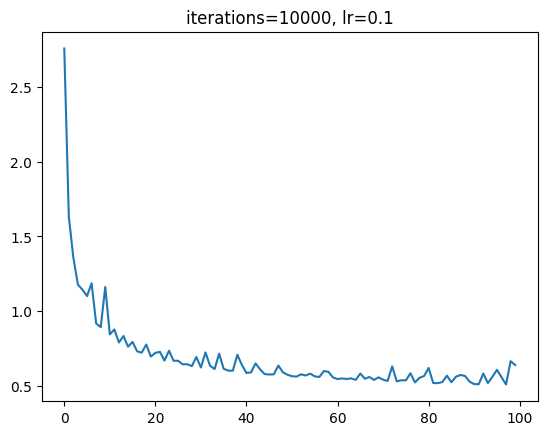

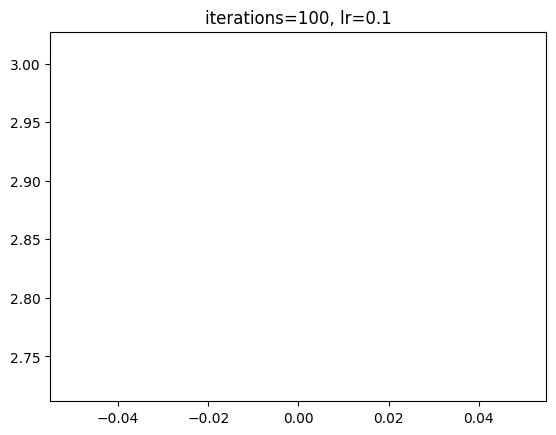

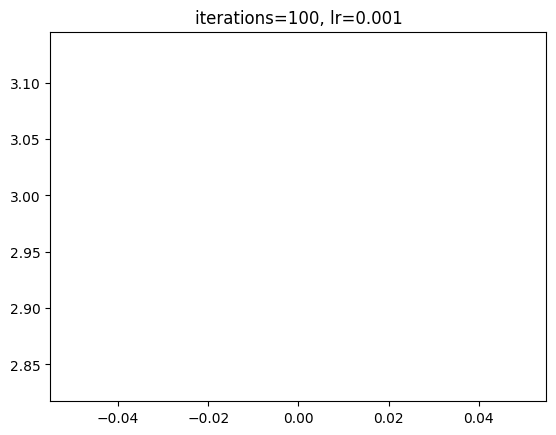

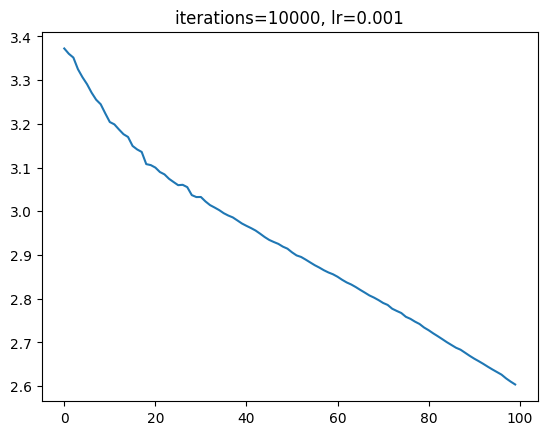

CPU times: user 667 ms, sys: 6.07 ms, total: 673 ms
Wall time: 676 ms


In [14]:
%%time

# train Changing lr and iterations value (in class activity)
import time

def train_run2(iterations, learning_rate): # we will change iterations and lr value
    #random init of weights
    w1 = np.random.randn()
    w2 = np.random.randn()
    b = np.random.randn()

    #iterations = 100
    #learning_rate = 0.1
    costs = [] # keep costs during training, see if they go down

    for i in range(iterations):
        # get a random point
        ri = np.random.randint(len(data))
        point = data[ri]

        z = point[0] * w1 + point[1] * w2 + b
        pred = sigmoid(z) # networks prediction

        target = point[2]

        # cost for current random point
        cost = np.square(pred - target)

        # print the cost over all data points every 1k iters
        if i % 100 == 0:
            c = 0
            for j in range(len(data)):
                p = data[j]
                p_pred = sigmoid(w1 * p[0] + w2 * p[1] + b)
                c += np.square(p_pred - p[2])
            costs.append(c)

        dcost_dpred = 2 * (pred - target)
        dpred_dz = sigmoid_p(z)

        dz_dw1 = point[0]
        dz_dw2 = point[1]
        dz_db = 1

        dcost_dz = dcost_dpred * dpred_dz

        dcost_dw1 = dcost_dz * dz_dw1
        dcost_dw2 = dcost_dz * dz_dw2
        dcost_db = dcost_dz * dz_db

        w1 = w1 - learning_rate * dcost_dw1
        w2 = w2 - learning_rate * dcost_dw2
        b = b - learning_rate * dcost_db

    return costs, w1, w2, b

# CHANGE 4: loop over every combination as mentioned
itlr = [(10000, 0.1), (100, 0.1), (100, 0.001), (10000, 0.001)]

for it, lr in itlr:
    start = time.time()
    costs, w1, w2, b = train_run2(it, lr)
    fig = plt.plot(costs)
    plt.title(f"iterations={it}, lr={lr}")
    plt.show()

In [15]:
# predict what the myster flower is!

z = w1 * mystery_flower[0] + w2 * mystery_flower[1] + b
pred = sigmoid(z)

print(pred)
print("close to 0 -> blue, close to 1 -> red")

0.7359673077712529
close to 0 -> blue, close to 1 -> red


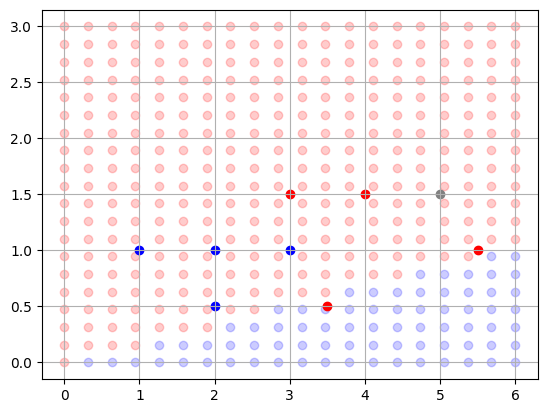

In [16]:
# check out the networks predictions in the x,y plane
for x in np.linspace(0, 6, 20):
    for y in np.linspace(0, 3, 20):
        pred = sigmoid(w1 * x + w2 * y + b)
        c = 'b'
        if pred > .5:
            c = 'r'
        plt.scatter([x],[y],c=c, alpha=.2)

# plot points over network predictions
# you should see a split, with half the predictions blue
# and the other half red.. nicely predicting each data point!
vis_data()

In [17]:
# Part 2 – One-hot vectors: In class activity
S1 = "New York Times"
S2 = "Los Angeles Times"
S3 = "Los Angeles York"

V = ['New', 'York', 'Times', 'Los', 'Angeles']   # vocabulary, 5 unique words
print(len(V))

# Sentence vectors (1 = word present, 0 = absent) Applying One hot encoding to the sentences
# S1= [1 1 1 0 0]
# S2= [0 0 1 1 1]
# S3= [0 1 0 1 1]

def sentence_vector(sentence):
    words = sentence.split()
    return [1 if w in words else 0 for w in V]

s1 = sentence_vector(S1)
s2 = sentence_vector(S2)
s3 = sentence_vector(S3)

print("S1:", s1)   # expected [1, 1, 1, 0, 0]
print("S2:", s2)   # expected [0, 0, 1, 1, 1]
print("S3:", s3)   # expected [0, 1, 0, 1, 1]

# Layer 1 – lookup function h (h is a matrix of size 3×5)
# s=h*w

import numpy as np

h = np.array([s1, s2, s3])
print("h matrix")
print (h)
print("h shape:", h.shape)    # (3, 5)

# Layer 2 – S = h · W  (h: 3×5, W: 5×2, output S: 3×2)

W = np.random.randn(5, 2)     # 5 vocabulary words -> 2 output neurons, random values
S = np.dot(h, W)              # use np.dot

print("W shape:", W.shape)    # (5, 2)
print ("w",W)
print("Output matrix: S shape:", S.shape)    # (3, 2)
print(S)


5
S1: [1, 1, 1, 0, 0]
S2: [0, 0, 1, 1, 1]
S3: [0, 1, 0, 1, 1]
h matrix
[[1 1 1 0 0]
 [0 0 1 1 1]
 [0 1 0 1 1]]
h shape: (3, 5)
W shape: (5, 2)
w [[ 0.51568373  1.99897092]
 [ 0.50087074  1.48847122]
 [-1.15907493 -0.54025496]
 [ 0.01661293  1.34352281]
 [-1.79153642  3.01775395]]
Output matrix: S shape: (3, 2)
[[-0.14252045  2.94718718]
 [-2.93399842  3.8210218 ]
 [-1.27405275  5.84974798]]


In [18]:
import numpy as np

# 1. Corpus  (CHANGED: your sentences instead of cats/dogs)
import numpy as np

S1 = "New York Times"
S2 = "Los Angeles Times"
S3 = "Los Angeles York"

corpus = [S1, S2, S3]
corpus = [S1, S2, S3]       # "New York Times", "Los Angeles Times", "Los Angeles York"

# 2. Build vocabulary  (same as hers)
sentences = [s.split() for s in corpus]
vocab = sorted(set(word for s in sentences for word in s))

word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = {i: word for word, i in word_to_id.items()}

V = len(vocab)
print("Vocabulary:", vocab)

# Hyperparameters  (same as hers)
window = 1
d = 3
learning_rate = 0.05
epochs = 500

# 3. Generate center-context training pairs
pairs = []

for sentence in sentences:
    ids = [word_to_id[w] for w in sentence]

    for i, center in enumerate(ids):
        for j in range(max(0, i - window),
                       min(len(ids), i + window + 1)):
            if i != j:
                pairs.append((center, ids[j]))

print("Training pairs:", pairs)
E = np.eye(V)                         # (5, 5), row i = one-hot of word i
W = np.random.randn(V, V) * 0.1       # (5, 5), because the embedding length is now V



Vocabulary: ['Angeles', 'Los', 'New', 'Times', 'York']
Training pairs: [(2, 4), (4, 2), (4, 3), (3, 4), (1, 0), (0, 1), (0, 3), (3, 0), (1, 0), (0, 1), (0, 4), (4, 0)]



Learned word embeddings:
Angeles [-1.588 -0.346 -0.034]
Los [ 2.331  1.687 -0.478]
New [-1.165  2.113  0.964]
Times [0.375 2.028 0.239]
York [ 0.974 -0.78  -1.122]


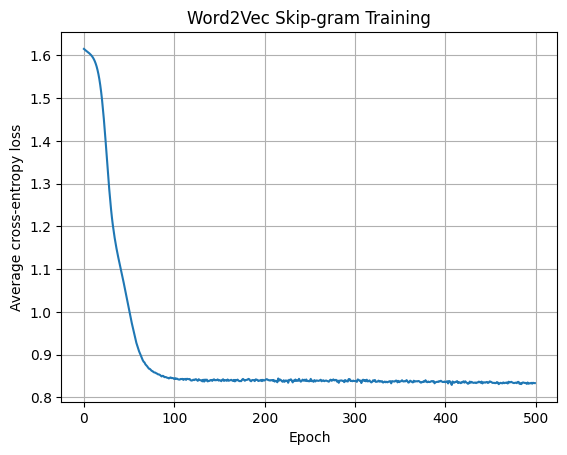

In [23]:
# 4. Initialize parameters randomly
np.random.seed(42)

E = np.random.randn(V, d) * 0.1
W = np.random.randn(d, V) * 0.1

# 5. Softmax function
def softmax(x):
    x = x - np.max(x)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x)

# 6. Train Skip-gram
losses = []

for epoch in range(epochs):
    np.random.shuffle(pairs)
    total_loss = 0

    for center, context in pairs:

        # Forward pass
        h = E[center].copy()
        scores = h @ W
        probabilities = softmax(scores)

        # Cross-entropy loss
        loss = -np.log(probabilities[context] + 1e-12)
        total_loss += loss

        # Backpropagation
        error = probabilities.copy()
        error[context] -= 1

        gradient_W = np.outer(h, error)
        gradient_h = W @ error

        # Update parameters
        W -= learning_rate * gradient_W
        E[center] -= learning_rate * gradient_h

    losses.append(total_loss / len(pairs))

# 7. Print learned embeddings
print("\nLearned word embeddings:")
for word, idx in word_to_id.items():
    print(word, np.round(E[idx], 3))

# 8. Plot training loss
import matplotlib.pyplot as plt

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Average cross-entropy loss")
plt.title("Word2Vec Skip-gram Training")
plt.grid(True)
plt.show()

E_sm, W_sm = E.copy(), W.copy()
losses_sm = list(losses)

In [20]:
def cosine_similarity(a, b):
    return np.dot(a, b) / (
        np.linalg.norm(a) * np.linalg.norm(b) + 1e-12
    )

def similar_words(word, top_k=3):
    idx = word_to_id[word]
    scores = []

    for j in range(V):
        if j != idx:
            sim = cosine_similarity(E[idx], E[j])
            scores.append((id_to_word[j], sim))

    return sorted(scores, key=lambda x: x[1], reverse=True)[:top_k]

print("Words similar to York:", similar_words("York"))
print("Words similar to Times:", similar_words("Times"))
print("Words similar to Los:", similar_words("Los"))

Words similar to York: [('Los', np.float64(0.3147908723231429)), ('Times', np.float64(-0.390084224501097)), ('Angeles', np.float64(-0.4704947603624706))]
Words similar to Times: [('New', np.float64(0.738111918339096)), ('Los', np.float64(0.7108921707295619)), ('York', np.float64(-0.390084224501097))]
Words similar to Los: [('Times', np.float64(0.7108921707295619)), ('York', np.float64(0.3147908723231429)), ('New', np.float64(0.05280552356067259))]


loss at epoch 1: 2.7684610695908662  at end: 1.5482339545273271


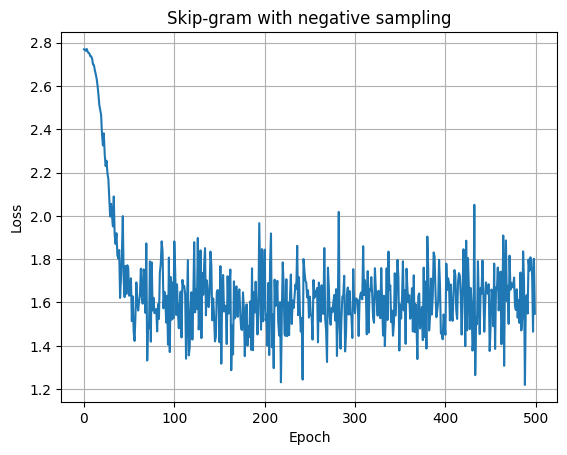

In [24]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

k = 3    # negatives per pair. With only 5 words, use k = 2 or 3

# Negative sampling distribution: word frequency ^ 0.75 (the standard choice)
counts = np.zeros(V)
for sentence in sentences:
    for w in sentence:
        counts[word_to_id[w]] += 1
neg_dist = counts ** 0.75
neg_dist = neg_dist / neg_dist.sum()

def sample_negatives(center, context, k):
    negatives = []
    while len(negatives) < k:
        n = np.random.choice(V, p=neg_dist)
        if n != context and n != center:      # a negative must not be the true context
            negatives.append(n)
    return negatives

np.random.seed(42)
E = np.random.randn(V, d) * 0.1
W = np.random.randn(d, V) * 0.1      # column j = output vector of word j

neg_losses = []

for epoch in range(epochs):
    np.random.shuffle(pairs)
    epoch_loss = 0

    for center, context in pairs:
        h = E[center].copy()

        # sampled words: 1 positive + k negatives
        words  = [context] + sample_negatives(center, context, k)
        labels = np.array([1] + [0] * k)

        # forward pass
        w_sel  = W[:, words]                 # shape (d, k+1)
        scores = h @ w_sel                   # shape (k+1,)
        probs  = sigmoid(scores)

        # loss
        epoch_loss += -np.sum(labels * np.log(probs + 1e-12)
                              + (1 - labels) * np.log(1 - probs + 1e-12))

        # backprop
        error = probs - labels               # shape (k+1,)
        grad_h = w_sel @ error               # shape (d,)
        grad_W = np.outer(h, error)          # shape (d, k+1)

        # update: only the sampled columns of W and the center row of E
        W[:, words] -= learning_rate * grad_W
        E[center]   -= learning_rate * grad_h

    neg_losses.append(epoch_loss / len(pairs))

print("loss at epoch 1:", neg_losses[0], " at end:", neg_losses[-1])
plt.plot(neg_losses); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Skip-gram with negative sampling"); plt.grid(True); plt.show()

E_ns, W_ns = E.copy(), W.copy()
losses_ns = list(neg_losses)

Full-softmax loss  | softmax: 0.752 | neg sampling: 3.24

Similar to York
  softmax      : [('Los', 0.304), ('Times', -0.426), ('Angeles', -0.454)]
  neg sampling : [('New', 0.93), ('Angeles', 0.887), ('Times', 0.531)]

Similar to Times
  softmax      : [('New', 0.756), ('Los', 0.69), ('Angeles', -0.387)]
  neg sampling : [('York', 0.531), ('Angeles', 0.486), ('New', 0.242)]

Similar to Los
  softmax      : [('Times', 0.69), ('York', 0.304), ('New', 0.051)]
  neg sampling : [('Angeles', 0.414), ('York', -0.034), ('New', -0.172)]


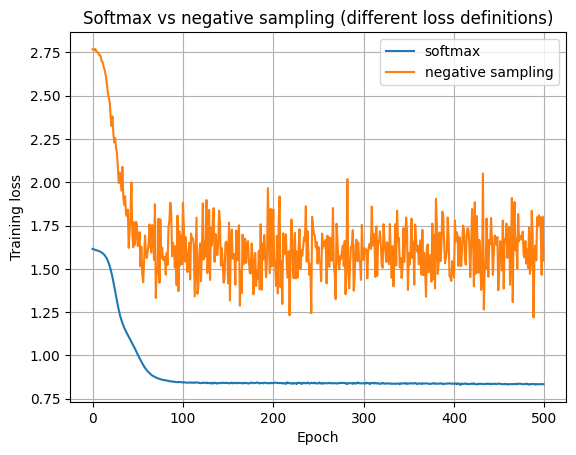

In [25]:
def similar_words_from(Emb, word, top_k=3):
    idx = word_to_id[word]
    s = [(id_to_word[j], round(float(cosine_similarity(Emb[idx], Emb[j])), 3))
         for j in range(V) if j != idx]
    return sorted(s, key=lambda x: x[1], reverse=True)[:top_k]

def full_softmax_loss(Emb, Wt):        # same yardstick for both models
    return np.mean([-np.log(softmax(Emb[c] @ Wt)[ctx] + 1e-12) for c, ctx in pairs])

print("Full-softmax loss  | softmax:", round(full_softmax_loss(E_sm, W_sm), 3),
      "| neg sampling:", round(full_softmax_loss(E_ns, W_ns), 3))

for w in ["York", "Times", "Los"]:
    print(f"\nSimilar to {w}")
    print("  softmax      :", similar_words_from(E_sm, w))
    print("  neg sampling :", similar_words_from(E_ns, w))

plt.plot(losses_sm, label="softmax")
plt.plot(losses_ns, label="negative sampling")
plt.xlabel("Epoch"); plt.ylabel("Training loss"); plt.legend(); plt.grid(True)
plt.title("Softmax vs negative sampling (different loss definitions)")
plt.show()